In [13]:
import numpy as np
from hcipy import *
from psfGenerator import PsfGenerator
import matplotlib.pyplot as plt

In [14]:
wavelength = 656E-9
bw = 120E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 40

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=50,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:37: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


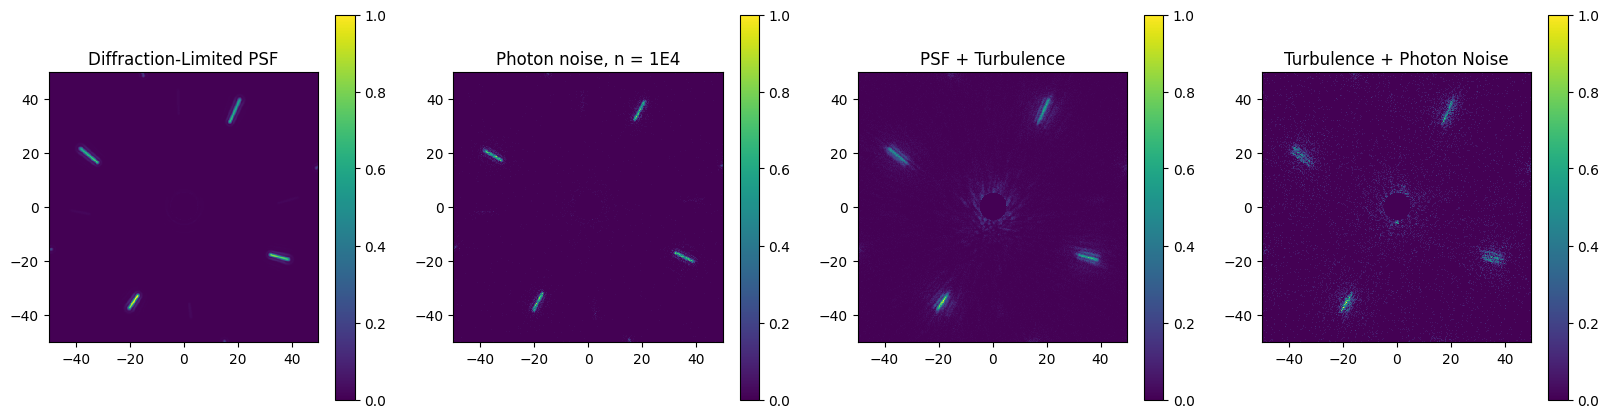

In [15]:
disp_x = np.random.rand() * 0.1
disp_y = np.random.rand() * 0.1

num_photons = 1E5
ptv = .7

psf = PsfGen.psf(magnitude_x=disp_x,magnitude_y=disp_y)
#psf /= psf.max()

psf_poisson = PsfGen.noisy_turbulent_psf(magnitude_x=disp_x,magnitude_y=disp_x,num_photons=num_photons,ptv=0)
#psf_poisson /= psf_poisson.max()

psf_turbulent = PsfGen.noisy_turbulent_psf(magnitude_x=disp_x,magnitude_y=disp_y,ptv=ptv)
#psf_turbulent /= psf_turbulent.max()

psf_poisson_turbulent = PsfGen.noisy_turbulent_psf(magnitude_x=disp_x,magnitude_y=disp_y,ptv=ptv,num_photons=num_photons)
#psf_poisson_turbulent /= psf_poisson_turbulent.max()

plt.figure(figsize=(20,5))

plt.subplot(1,4,1)
imshow_field(psf)
plt.title('Diffraction-Limited PSF')
plt.colorbar()

plt.subplot(1,4,2)
imshow_field(psf_poisson)
plt.title('Photon noise, n = 1E4')
plt.colorbar()

plt.subplot(1,4,3)
imshow_field(psf_turbulent)
plt.title('PSF + Turbulence')
plt.colorbar()

plt.subplot(1,4,4)
imshow_field(psf_poisson_turbulent)
plt.title('Turbulence + Photon Noise')
plt.colorbar()

plt.tight_layout
plt.show() 